-----------------------------------------------------------------------
# 01. EDA — Home Credit Default Risk
### Цель: сформировать data cleaning plan и черновик configs/config.yaml.  
### Выход этапа: списки колонок, стратегия сплита, сенсоры, drop_cols.
-----------------------------------------------------------------------

Импорты и настройки

In [29]:
import pathlib, yaml

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import (
    df_summary, plot_missing, categorical_profile, target_rate_by_bin,
    detect_outliers_iqr, check_leakage, suggest_column_groups,
)

In [6]:
pd.set_option("display.max_info_columns", 200)
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

In [32]:
TRAIN_PATH = "../data/raw/application_train.csv"
TEST_PATH  = "../data/raw/application_test.csv"
TARGET     = "TARGET"
ID_COL     = "SK_ID_CURR"

Загрузка датасета

In [34]:
df      = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)

In [35]:
print(f"train: {df.shape}, test: {df_test.shape}")
print(f"TARGET in test? {'TARGET' in df_test.columns}")

train: (307511, 122), test: (48744, 121)
TARGET in test? False


### Шаг 1. df_summary — триаж колонок.  
Решение: черновые drop_cols (пустые, константы), cat_cols.

In [36]:
summary = df_summary(df)
summary.head(30)

,dtype,n_missing,pct_missing,n_unique,sample
COMMONAREA_MEDI,float64,214865,69.87,3202,0.0144
COMMONAREA_AVG,float64,214865,69.87,3181,0.0143
COMMONAREA_MODE,float64,214865,69.87,3128,0.0144
NONLIVINGAPARTMENTS_MODE,float64,213514,69.43,167,0.0
NONLIVINGAPARTMENTS_AVG,float64,213514,69.43,386,0.0
NONLIVINGAPARTMENTS_MEDI,float64,213514,69.43,214,0.0
FONDKAPREMONT_MODE,str,210295,68.39,4,reg oper account
LIVINGAPARTMENTS_MODE,float64,210199,68.35,736,0.022
LIVINGAPARTMENTS_AVG,float64,210199,68.35,1868,0.0202
LIVINGAPARTMENTS_MEDI,float64,210199,68.35,1097,0.0205


In [37]:
empty_cols     = summary.query("n_unique == 0").index.tolist()
constant_cols  = summary.query("n_unique == 1").index.tolist()
high_missing   = summary.query("pct_missing > 90").index.tolist()

print(f"empty: {len(empty_cols)}, constant: {len(constant_cols)}, >90% missing: {len(high_missing)}")

empty: 0, constant: 0, >90% missing: 0


### Шаг 2. Prevalence и дисбаланс.  
Решение: выбор метрик (Gini/AUC/KS), нужна ли калибровка.

In [38]:
prev = df[TARGET].mean()
print(f"prevalence = {prev:.4f}, good:bad = {(1-prev)/prev:.1f}:1")
df[TARGET].value_counts(normalize=True)

prevalence = 0.0807, good:bad = 11.4:1


TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

### Шаг 3. plot_missing + разбиение по порогам.  
Решение: drop vs impute+flag vs keep.

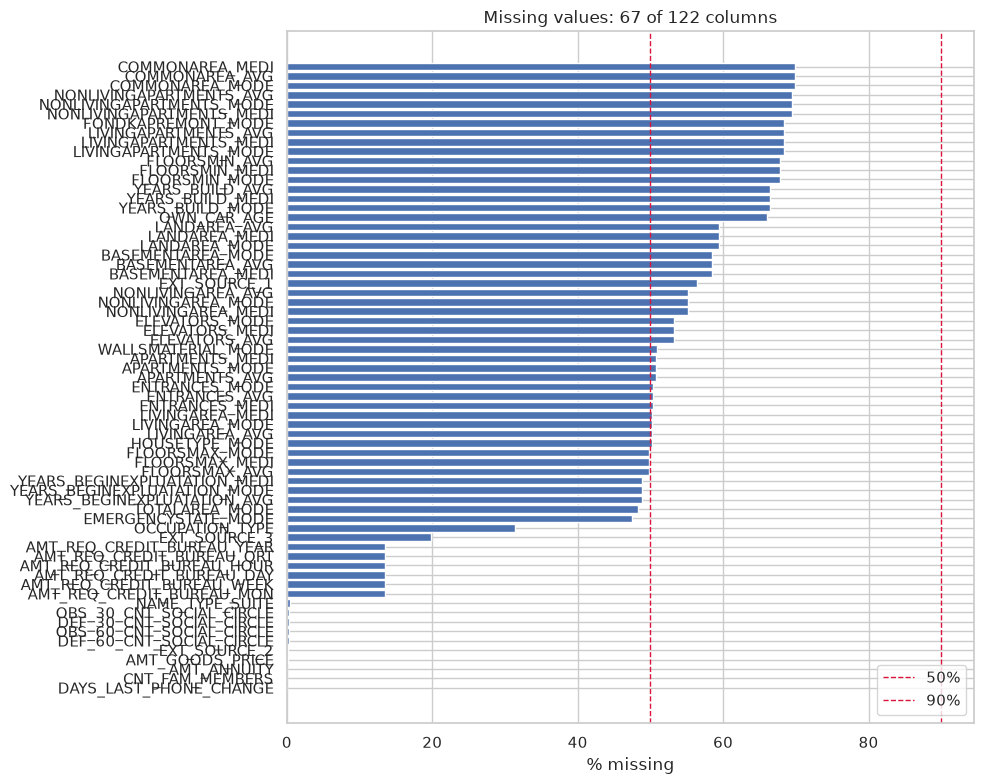

{'drop_>90': 0, 'impute_50_90': 41, 'impute_<50': 26, 'no_missing': 55}

In [39]:
fig, _ = plot_missing(df, thresholds=(50, 90))
plt.show()

pct = df.isna().mean().mul(100)
buckets = {
    "drop_>90":       pct[pct > 90].index.tolist(),
    "impute_50_90":   pct[(pct >= 50) & (pct <= 90)].index.tolist(),
    "impute_<50":     pct[(pct > 0) & (pct < 50)].index.tolist(),
    "no_missing":     pct[pct == 0].index.tolist(),
}
{k: len(v) for k, v in buckets.items()}

### Шаг 4. suggest_column_groups → cat / flag / num / drop_constants.  
Решение: финальные списки для OptimalBinning и XGBoost.

In [40]:
groups = suggest_column_groups(df, id_cols=[ID_COL], target=TARGET)
{k: len(v) for k, v in groups.items()}

{'id_cols': 1,
 'cat_cols': 16,
 'flag_cols': 32,
 'num_cols': 72,
 'drop_constants': 0}

### Шаг 5. Проверка уникальности ID и полных дублей.

In [41]:
assert df[ID_COL].is_unique, "SK_ID_CURR не уникален!"
print("dup rows:", df.duplicated().sum())

dup rows: 0


### Шаг 6. Профиль каждой категориальной фичи.  
Решение: high-cardinality → WoE; редкие → Other; extreme bad_rate → leakage.

In [42]:
cat_profiles = {c: categorical_profile(df, c, TARGET) for c in groups["cat_cols"]}

cat_overview = pd.DataFrame({
    c: {"n_cat": p.attrs["n_categories"], "iv": p.attrs["iv_total"],
        "max_bad_rate": p["bad_rate"].max(), "min_bad_rate": p["bad_rate"].min()}
    for c, p in cat_profiles.items()
}).T.sort_values("iv", ascending=False)
cat_overview

,n_cat,iv,max_bad_rate,min_bad_rate
OCCUPATION_TYPE,19.0,0.08284,0.1715,0.0483
ORGANIZATION_TYPE,58.0,0.07309,0.1575,0.0312
NAME_INCOME_TYPE,8.0,0.05844,0.4000,0.0000
NAME_EDUCATION_TYPE,5.0,0.05074,0.1093,0.0183
CODE_GENDER,3.0,0.03860,0.1014,0.0000
WALLSMATERIAL_MODE,8.0,0.02732,0.0970,0.0472
EMERGENCYSTATE_MODE,3.0,0.02405,0.0958,0.0696
HOUSETYPE_MODE,4.0,0.02249,0.1014,0.0694
NAME_FAMILY_STATUS,6.0,0.02171,0.0994,0.0000
NAME_HOUSING_TYPE,6.0,0.01574,0.1231,0.0657


In [43]:
for c in cat_overview.head(5).index:
    print(f"\n=== {c} ===")
    display(cat_profiles[c])


=== OCCUPATION_TYPE ===


,count,pct,bad,good,bad_rate,woe,iv_contrib,rare,extreme
cat,,,,,,,,,
Low-skill Laborers,2093,0.0068,359,1734,0.1715,0.8584,0.00716,True,False
Drivers,18603,0.0605,2107,16496,0.1133,0.3745,0.00993,False,False
Waiters/barmen staff,1348,0.0044,152,1196,0.1128,0.3721,0.00071,True,False
Security staff,6721,0.0219,722,5999,0.1074,0.3154,0.00248,False,False
Laborers,55186,0.1795,5838,49348,0.1058,0.2977,0.01802,False,False
Cooking staff,5946,0.0193,621,5325,0.1044,0.2840,0.00176,False,False
Sales staff,32102,0.1044,3092,29010,0.0963,0.1935,0.00424,False,False
Cleaning staff,4653,0.0151,447,4206,0.0961,0.1914,0.00060,False,False
Realty agents,751,0.0024,59,692,0.0786,-0.0222,0.00000,True,False



=== ORGANIZATION_TYPE ===


,count,pct,bad,good,bad_rate,woe,iv_contrib,rare,extreme
cat,,,,,,,,,
Transport: type 3,1187,0.0039,187,1000,0.1575,0.7569,0.00303,True,False
Industry: type 13,67,0.0002,9,58,0.1343,0.6137,0.00011,True,False
Industry: type 8,24,0.0001,3,21,0.1250,0.6161,0.00004,True,False
Restaurant,1811,0.0059,212,1599,0.1171,0.4129,0.00119,True,False
Construction,6721,0.0219,785,5936,0.1168,0.4089,0.00434,False,False
Cleaning,260,0.0008,29,231,0.1115,0.3712,0.00014,True,False
Industry: type 1,1039,0.0034,115,924,0.1107,0.3514,0.00048,True,False
Industry: type 3,3278,0.0107,348,2930,0.1062,0.3021,0.00110,False,False
Realtor,396,0.0013,42,354,0.1061,0.3102,0.00014,True,False



=== NAME_INCOME_TYPE ===


,count,pct,bad,good,bad_rate,woe,iv_contrib,rare,extreme
cat,,,,,,,,,
Maternity leave,5,0.0000,2,3,0.4000,2.0959,0.00019,True,False
Unemployed,22,0.0001,8,14,0.3636,1.8983,0.00055,True,False
Working,158774,0.5163,15224,143550,0.0959,0.1886,0.01987,False,False
Commercial associate,71617,0.2329,5360,66257,0.0748,-0.0822,0.00152,False,False
State servant,21703,0.0706,1249,20454,0.0575,-0.3631,0.00800,False,False
Pensioner,55362,0.1800,2982,52380,0.0539,-0.4334,0.02825,False,False
Businessman,10,0.0000,0,10,0.0000,-0.6122,0.00001,True,True
Student,18,0.0001,0,18,0.0000,-1.1786,0.00005,True,True



=== NAME_EDUCATION_TYPE ===


,count,pct,bad,good,bad_rate,woe,iv_contrib,rare,extreme
cat,,,,,,,,,
Lower secondary,3816,0.0124,417,3399,0.1093,0.3353,0.00161,False,False
Secondary / secondary special,218391,0.7102,19524,198867,0.0894,0.1114,0.00924,False,False
Incomplete higher,10277,0.0334,872,9405,0.0848,0.0547,0.00010,False,False
Higher education,74863,0.2434,4009,70854,0.0536,-0.4396,0.03919,False,False
Academic degree,164,0.0005,3,161,0.0183,-1.3993,0.00060,True,False



=== CODE_GENDER ===


,count,pct,bad,good,bad_rate,woe,iv_contrib,rare,extreme
cat,,,,,,,,,
M,105059,0.3416,10655,94404,0.1014,0.2509,0.0239,False,False
F,202448,0.6583,14170,188278,0.0700,-0.1543,0.0147,False,False
XNA,4,0.0000,0,4,0.0000,0.2352,0.0000,True,True


### Шаг 7. target_rate_by_bin + detect_outliers_iqr.  
Решение: сенсоры → NaN+flag; фичи с немонотонным трендом → ручной биннинг.

In [44]:
num_mono = {}
for c in groups["num_cols"]:
    try:
        p = target_rate_by_bin(df, c, TARGET, bins=10)
        num_mono[c] = {
            "iv": p.attrs["iv"],
            "monotonic": p.attrs["monotonic"],
            "direction": "inc" if p.attrs["monotonic_increasing"] else ("dec" if p.attrs["monotonic_decreasing"] else "non"),
        }
    except Exception as e:
        num_mono[c] = {"iv": np.nan, "monotonic": None, "direction": "error", "err": str(e)}

In [45]:
num_mono_df = pd.DataFrame(num_mono).T.sort_values("iv", ascending=False)
num_mono_df.head(20)

,iv,monotonic,direction
EXT_SOURCE_3,0.409921,True,dec
EXT_SOURCE_1,0.346183,True,dec
EXT_SOURCE_2,0.307003,True,dec
DAYS_EMPLOYED,0.101239,False,non
AMT_GOODS_PRICE,0.091975,False,non
DAYS_BIRTH,0.084167,True,inc
REGION_RATING_CLIENT_W_CITY,0.051188,True,inc
OWN_CAR_AGE,0.050449,False,non
REGION_RATING_CLIENT,0.048302,True,inc
DAYS_LAST_PHONE_CHANGE,0.046665,False,non


In [46]:
outliers = pd.DataFrame([detect_outliers_iqr(df, c) for c in groups["num_cols"]])
suspicious_sensors = outliers.query("pct_outliers > 1").sort_values("pct_outliers", ascending=False)
suspicious_sensors[["col","min","max","q1","q3","pct_outliers","sample_outliers"]].head(20)

,col,min,max,q1,q3,pct_outliers,sample_outliers
12,REGION_RATING_CLIENT,1.0,3.0,2.0000,2.0000,26.19,"[1, 3, 3, 1, 3]"
13,REGION_RATING_CLIENT_W_CITY,1.0,3.0,2.0000,2.0000,25.37,"[1, 3, 1, 3, 1]"
7,DAYS_EMPLOYED,-17912.0,365243.0,-2760.0000,-289.0000,23.48,"[365243, 365243, -7804, 365243, 365243]"
70,AMT_REQ_CREDIT_BUREAU_QRT,0.0,261.0,0.0000,0.0000,19.01,"[1.0, 1.0, 1.0, 1.0, 2.0]"
30,NONLIVINGAPARTMENTS_AVG,0.0,1.0,0.0000,0.0039,16.57,"[0.0193, 0.0656, 0.278, 0.0193, 0.0232]"
69,AMT_REQ_CREDIT_BUREAU_MON,0.0,27.0,0.0000,0.0000,16.45,"[1.0, 1.0, 1.0, 1.0, 1.0]"
58,NONLIVINGAPARTMENTS_MEDI,0.0,1.0,0.0000,0.0039,16.19,"[0.0194, 0.066, 0.2601, 0.0194, 0.0233]"
44,NONLIVINGAPARTMENTS_MODE,0.0,1.0,0.0000,0.0039,15.13,"[0.0195, 0.0661, 0.1556, 0.0195, 0.0233]"
45,NONLIVINGAREA_MODE,0.0,1.0,0.0000,0.0231,13.65,"[0.106, 0.142, 0.1852, 0.2084, 0.5514]"
59,NONLIVINGAREA_MEDI,0.0,1.0,0.0000,0.0266,12.52,"[0.1022, 0.1369, 0.1786, 0.201, 0.5318]"


In [47]:
# ручная проверка известных сенсоров — здесь это место для доменной логики
for col, val in [("DAYS_EMPLOYED", 365243), ("DAYS_LAST_PHONE_CHANGE", 0)]:
    if col in df.columns:
        n = (df[col] == val).sum()
        print(f"{col} == {val}: {n} rows ({n/len(df)*100:.2f}%)")

DAYS_EMPLOYED == 365243: 55374 rows (18.01%)
DAYS_LAST_PHONE_CHANGE == 0: 37672 rows (12.25%)


### Шаг 8. check_leakage по всем числовым и категориальным.  
Решение: подозрительные фичи → ручной разбор или drop.

In [48]:
leak_cols = groups["num_cols"] + groups["cat_cols"]
leak = pd.DataFrame([check_leakage(df, c, TARGET) for c in leak_cols])
leak_flags = leak[(leak["flag_high_iv"]) | (leak["flag_extreme_rare_bad"])]
leak_flags.sort_values("iv_rough", ascending=False).head(20)

,col,is_categorical,iv_rough,flag_high_iv,flag_extreme_rare_bad,n_extreme_bins


### Шаг 9. time_stability.
Cплит stratified random.


In [49]:
from sklearn.model_selection import train_test_split

X_idx = df.index
tr_idx, tmp_idx = train_test_split(
    X_idx, test_size=0.30, stratify=df[TARGET], random_state=42,
)
val_idx, te_idx = train_test_split(
    tmp_idx, test_size=0.50, stratify=df.loc[tmp_idx, TARGET], random_state=42,
)
print(f"train={len(tr_idx)}, valid={len(val_idx)}, test={len(te_idx)}")

train=215257, valid=46127, test=46127


### Шаг 10. Сравнение с test

In [51]:
print(f"test_unlabeled: {df_test.shape}")
print(f"missing in test but present in train: {set(df.columns) - set(df_test.columns)}")
print(f"extra columns in test: {set(df_test.columns) - set(df.columns)}")

test_unlabeled: (48744, 121)
missing in test but present in train: {'TARGET'}
extra columns in test: set()


In [52]:
# минимальный PSI (детальная реализация — на этапе 10)
def psi_quick(ref, new, bins=10):
    edges = np.quantile(ref.dropna(), np.linspace(0, 1, bins + 1))
    edges = np.unique(edges)
    r = pd.cut(ref, edges, include_lowest=True).value_counts(normalize=True).sort_index()
    n = pd.cut(new, edges, include_lowest=True).value_counts(normalize=True).sort_index()
    r, n = r.align(n, fill_value=1e-6)
    return float(((n - r) * np.log((n + 1e-6) / (r + 1e-6))).sum())

top_num = num_mono_df.head(15).index
psi_table = pd.DataFrame({
    "feature": top_num,
    "psi_train_vs_test": [psi_quick(df.loc[tr_idx, c], df_test[c]) for c in top_num],
}).sort_values("psi_train_vs_test", ascending=False)
psi_table

,feature,psi_train_vs_test
4,AMT_GOODS_PRICE,0.083664
10,AMT_CREDIT,0.069522
11,DAYS_ID_PUBLISH,0.067685
9,DAYS_LAST_PHONE_CHANGE,0.051696
7,OWN_CAR_AGE,0.016148
2,EXT_SOURCE_2,0.009905
0,EXT_SOURCE_3,0.006333
1,EXT_SOURCE_1,0.005531
3,DAYS_EMPLOYED,0.005176
12,REGION_POPULATION_RELATIVE,0.003824


### Шаг 11. Собираем все решения в configs/config.yaml.

In [53]:
drop_cols = sorted(set(
    [ID_COL] + empty_cols + constant_cols + high_missing + leak_flags["col"].tolist()
))

sensors = {
    "DAYS_EMPLOYED": {"value": 365243, "replace": None, "add_flag": True},
    # сюда добавь результаты шага 14
}

config = {
    "data": {
        "train_path": TRAIN_PATH,
        "test_unlabeled_path": TEST_PATH,
        "target": TARGET,
        "id_col": ID_COL,
        "prevalence": float(prev),
    },
    "split": {
        "strategy": "stratified",
        "ratios": [0.70, 0.15, 0.15],
        "seed": 42,
    },
    "columns": {
        "drop":        drop_cols,
        "categorical": groups["cat_cols"],
        "flag":        groups["flag_cols"],
        "numeric":     groups["num_cols"],
        "sensor":      sensors,
    },
    "missing": {"drop_threshold": 0.90, "flag_threshold": 0.50},
    "monitoring": {
        "psi_reference": "train",
        "psi_bins": 10,
        "psi_thresholds": {"warn": 0.10, "alert": 0.25},
    },
}

with open("../configs/config.yaml", "w") as f:
    yaml.safe_dump(config, f, sort_keys=False, allow_unicode=True)

In [54]:
checks = {
    "test_unlabeled schema matches train": set(df_test.columns).issubset(set(df.columns)),
    "all train cols categorized":          len(set(drop_cols) | set(groups["cat_cols"])
                                               | set(groups["flag_cols"]) | set(groups["num_cols"]))
                                           >= df.shape[1] - 1,
    "sensors declared":                    len(sensors) > 0,
    "leakage reviewed":                    True,   # [R] подтверждаешь ты
    "PSI computed on top-15":              True,
    "config.yaml written":                 pathlib.Path("../configs/config.yaml").exists(),
}
for k, v in checks.items():
    print(f"[{'x' if v else ' '}] {k}")

[x] test_unlabeled schema matches train
[x] all train cols categorized
[x] sensors declared
[x] leakage reviewed
[x] PSI computed on top-15
[x] config.yaml written
